In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
from pathlib import Path
DATA_PATH = Path("../data/sales_data.csv")
df = pd.read_csv(DATA_PATH)
print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (10, 6)


,order_id,product,category,units_sold,unit_price,region
0,1001,Mouse,Electronics,3,799,North
1,1002,Notebook,Stationery,10,60,East
2,1003,Desk Lamp,Home,2,1299,South
3,1004,Keyboard,Electronics,2,1499,West
4,1005,Pen Set,Stationery,8,120,North


In [4]:
print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nDataset information:")
df.info()
print("\nStatistical summary:")
display(df.describe(include="all"))

Rows and columns: (10, 6)

Column names:
['order_id', 'product', 'category', 'units_sold', 'unit_price', 'region']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   order_id    10 non-null     int64
 1   product     10 non-null     str  
 2   category    10 non-null     str  
 3   units_sold  10 non-null     int64
 4   unit_price  10 non-null     int64
 5   region      10 non-null     str  
dtypes: int64(3), str(3)
memory usage: 612.0 bytes

Statistical summary:


,order_id,product,category,units_sold,unit_price,region
count,10.00000,10,10,10.000000,10.000000,10
unique,NaN,6,3,NaN,NaN,4
top,NaN,Mouse,Electronics,NaN,NaN,North
freq,NaN,2,4,NaN,NaN,3
mean,1005.50000,NaN,NaN,5.000000,783.300000,NaN
std,3.02765,NaN,NaN,3.741657,595.428706,NaN
min,1001.00000,NaN,NaN,1.000000,60.000000,NaN
25%,1003.25000,NaN,NaN,2.250000,189.750000,NaN
50%,1005.50000,NaN,NaN,3.500000,799.000000,NaN
75%,1007.75000,NaN,NaN,7.250000,1299.000000,NaN


In [5]:
print("Missing values in each column:")
display(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nDuplicate Order IDs:", df["order_id"].duplicated().sum())

Missing values in each column:


order_id      0
product       0
category      0
units_sold    0
unit_price    0
region        0
dtype: int64


Total missing values: 0

Duplicate rows: 0

Duplicate Order IDs: 0


In [6]:
df["revenue"] = df["units_sold"] * df["unit_price"]
product_analysis = (
    df.groupby("product").agg( total_units=("units_sold", "sum"), total_revenue=("revenue", "sum")).sort_values("total_revenue", ascending=False)
)
print("Product-wise Analysis:")
display(product_analysis)
category_analysis = (
    df.groupby("category").agg( total_units=("units_sold", "sum"), total_revenue=("revenue", "sum")).sort_values("total_revenue", ascending=False)
)
print("\nCategory-wise Analysis:")
display(category_analysis)

Product-wise Analysis:


,total_units,total_revenue
product,,
Keyboard,5,7495
Mouse,8,6392
Desk Lamp,3,3897
Water Bottle,4,1596
Notebook,22,1320
Pen Set,8,960



Category-wise Analysis:


,total_units,total_revenue
category,,
Electronics,13,13887
Home,7,5493
Stationery,30,2280


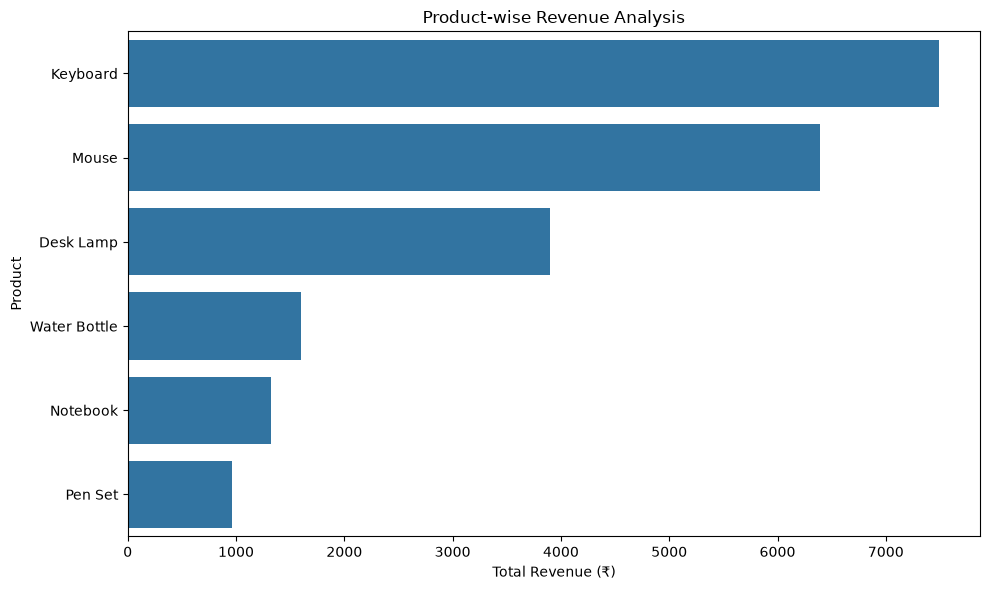

In [7]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=product_analysis.reset_index(),x="total_revenue",y="product"
)
plt.title("Product-wise Revenue Analysis")
plt.xlabel("Total Revenue (₹)")
plt.ylabel("Product")
plt.tight_layout()
plt.savefig(
    "../outputs/eda_product_revenue.png",dpi=300, bbox_inches="tight"
)
plt.show()

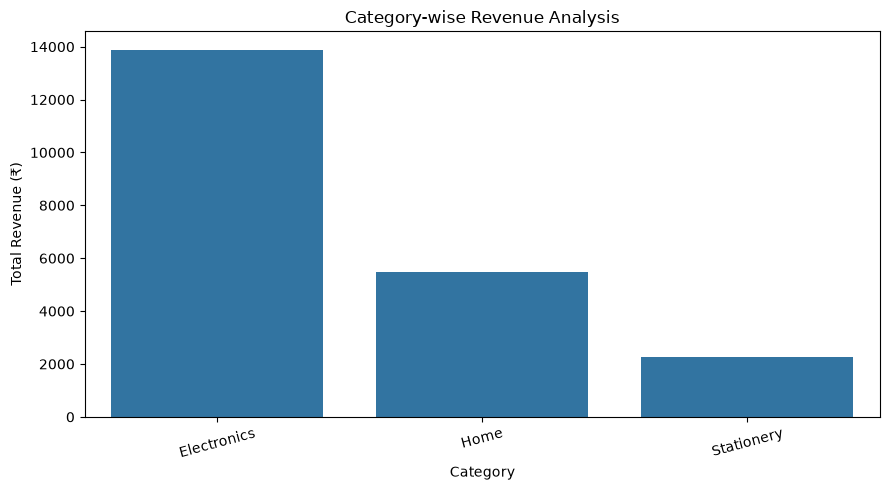

In [8]:
plt.figure(figsize=(9, 5))
category_plot = category_analysis.reset_index()
sns.barplot(
    data=category_plot,x="category",y="total_revenue"
)
plt.title("Category-wise Revenue Analysis")
plt.xlabel("Category")
plt.ylabel("Total Revenue (₹)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(
    "../outputs/eda_category_revenue.png",dpi=300,bbox_inches="tight"
)
plt.show()

Correlation Matrix:


,units_sold,unit_price,revenue
units_sold,1.000000,-0.873023,-0.575099
unit_price,-0.873023,1.000000,0.720014
revenue,-0.575099,0.720014,1.000000


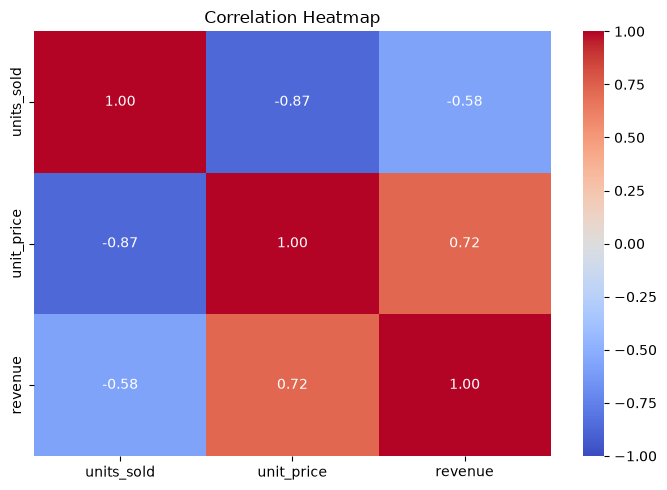

In [9]:
numeric_columns = [
    "units_sold",
    "unit_price",
    "revenue"
]
correlation_matrix = df[numeric_columns].corr()
print("Correlation Matrix:")
display(correlation_matrix)
plt.figure(figsize=(7, 5))
sns.heatmap(
    correlation_matrix,annot=True,cmap="coolwarm",fmt=".2f",vmin=-1,vmax=1
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig(
    "../outputs/eda_correlation_heatmap.png",dpi=300,bbox_inches="tight"
)
plt.show()

In [10]:
numeric_columns = ["units_sold", "unit_price", "revenue"]
for column in numeric_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[
        (df[column] < lower_bound) | (df[column] > upper_bound)
    ]
    print(f"\nColumn: {column}")
    print("Lower bound:", round(lower_bound, 2))
    print("Upper bound:", round(upper_bound, 2))
    print("Number of outliers:", len(outliers))
    if not outliers.empty:
        display(outliers[["order_id", column]])


Column: units_sold
Lower bound: -5.25
Upper bound: 14.75
Number of outliers: 0

Column: unit_price
Lower bound: -1474.12
Upper bound: 2962.88
Number of outliers: 0

Column: revenue
Lower bound: -1735.12
Upper bound: 5677.88
Number of outliers: 0


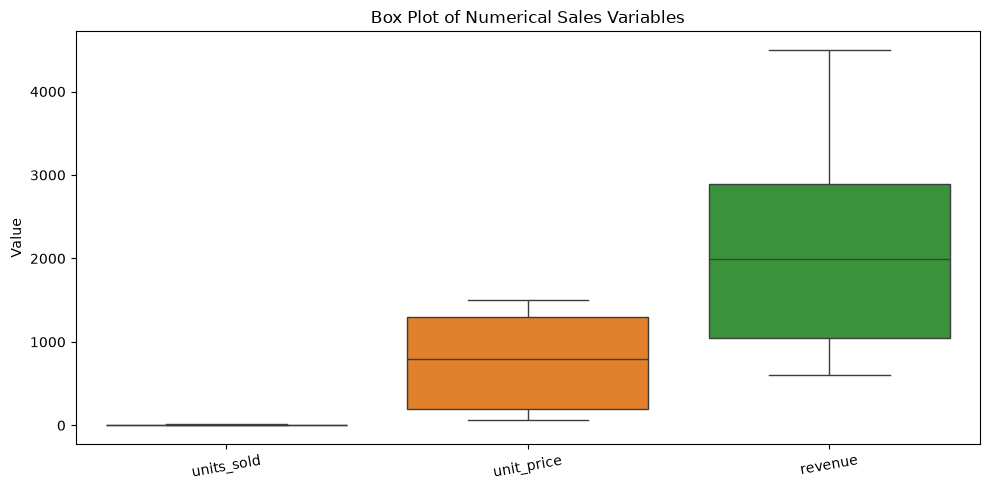

In [11]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df[numeric_columns])
plt.title("Box Plot of Numerical Sales Variables")
plt.ylabel("Value")
plt.xticks(rotation=10)
plt.tight_layout()
plt.savefig(
    "../outputs/eda_outlier_boxplots.png",dpi=300,bbox_inches="tight"
)
plt.show()

In [12]:
print("-----EDA SUMMARY-----")
print("Total records:", len(df))
print("Total columns:", len(df.columns))
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\n-----REVENUE SUMMARY-----")
print("Total revenue: ₹", round(df["revenue"].sum(), 2))
print("Average order revenue: ₹", round(df["revenue"].mean(), 2))
print("Highest order revenue: ₹", round(df["revenue"].max(), 2))
print("Lowest order revenue: ₹", round(df["revenue"].min(), 2))
print("\n-----TOP PERFORMERS-----")
print("Highest-revenue product:", product_analysis["total_revenue"].idxmax())
print("Highest-revenue category:", category_analysis["total_revenue"].idxmax())
region_analysis = (
    df.groupby("region")["revenue"].sum().sort_values(ascending=False)
)
print("\n-----REGION-WISE REVENUE-----")
display(region_analysis)

-----EDA SUMMARY-----
Total records: 10
Total columns: 7
Total missing values: 0
Duplicate rows: 0

-----REVENUE SUMMARY-----
Total revenue: ₹ 21660
Average order revenue: ₹ 2166.0
Highest order revenue: ₹ 4497
Lowest order revenue: ₹ 600

-----TOP PERFORMERS-----
Highest-revenue product: Keyboard
Highest-revenue category: Electronics

-----REGION-WISE REVENUE-----


region
East     6693
South    6593
North    4656
West     3718
Name: revenue, dtype: int64